LABORATORIUM 6 – CHAR-RNN

Pobieranie tekstu...
Korpus: Lalka – tom pierwszy
Autor: Bolesław Prus
Źródło: Wolne Lektury
Liczba znaków: 769287

Fragment tekstu:
Bolesław Prus Lalka ISBN 978-83-288-2673-1 Tom I I. Jak wygląda firma J. Mincel i S. Wokulski przez szkło butelek? W początkach roku 1878, kiedy świat polityczny zajmował się pokojem san-stefańskim, wyborem nowego papieża albo szansami europejskiej wojny, warszawscy kupcy tudzież inteligencja pewnej okolicy Krakowskiego Przedmieścia niemniej gorąco interesowała się przyszłością galanteryjnego skle

PODZIAŁ DANYCH
Trening     :   615429 znaków (80.00%)
Walidacja   :    76929 znaków (10.00%)
Test        :    76929 znaków (10.00%)

SŁOWNIK ZNAKÓW I KODOWANIE
Rozmiar słownika: 101
Liczba znaków w słowniku: 100
Indeks UNK: 100

Znaki w słowniku:
" !'()*,-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz«»ÓàçéóöüąćęŁłńŚśŹźŻż–—”„…"

TEST KODOWANIA I DEKODOWANIA
Tekst oryginalny: 'Bolesław Prus Lalka ISBN 978-83-288-267

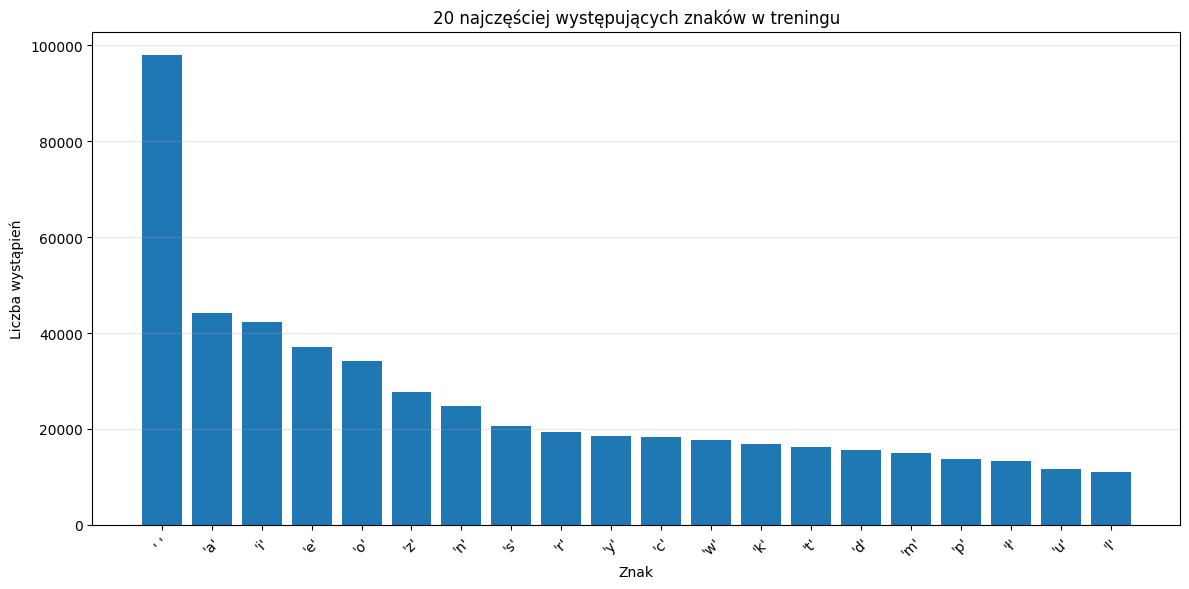


WYKRES LICZBY PAR DLA RÓŻNYCH SEKW


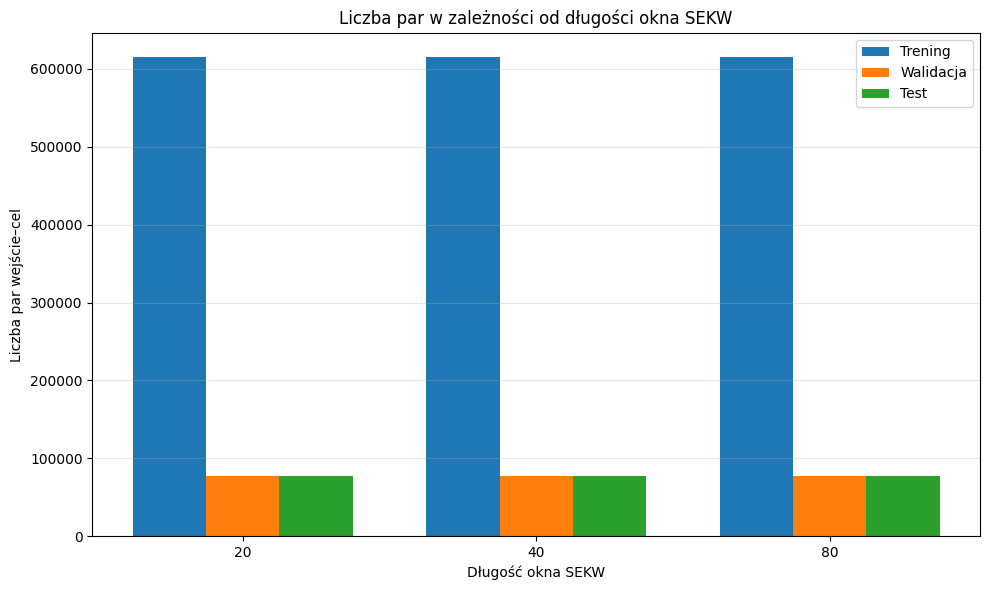


PODSUMOWANIE I WNIOSKI

1. Wykorzystano polski korpus literacki Lalka Bolesława Prusa.
2. Tekst został oczyszczony i podzielony na trening, walidację i test.
3. Podział danych wynosi odpowiednio 80%, 10% i 10%.
4. Słownik znaków utworzono na podstawie zbioru treningowego.
5. Zastosowano specjalny indeks UNK dla nieznanych znaków.
6. Utworzono osobne datasety i dataloadery dla każdego zbioru.
7. Cel Y jest przesunięty względem wejścia X o jeden znak.
8. Sprawdzono kształty tensorów i poprawność kodowania.
9. Porównano liczbę par dla SEKW = 20, 40 i 80.
10. Przy większej długości okna liczba dostępnych par maleje.
11. Przygotowane dane można wykorzystać do treningu modelu
    Char-RNN na laboratorium 7.

ZADANIE WYKONANE


In [1]:



import re
import html
import urllib.request
import numpy as np
import torch
import matplotlib.pyplot as plt

from collections import Counter
from torch.utils.data import Dataset, DataLoader



torch.manual_seed(0)
np.random.seed(0)

BATCH_SIZE = 32
SEKW = 40
WARTOSCI_SEKW = [20, 40, 80]

print("=" * 60)
print("LABORATORIUM 6 – CHAR-RNN")
print("=" * 60)


url = "https://wolnelektury.pl/media/book/txt/lalka-tom-pierwszy.txt"

print("\nPobieranie tekstu...")

req = urllib.request.Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(req, timeout=60) as response:
    tekst = response.read().decode("utf-8-sig")


tekst = html.unescape(tekst)
tekst = re.sub(r"<[^>]*>", " ", tekst)
tekst = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f]", "", tekst)
tekst = re.sub(r"\s+", " ", tekst).strip()

print("Korpus: Lalka – tom pierwszy")
print("Autor: Bolesław Prus")
print("Źródło: Wolne Lektury")
print("Liczba znaków:", len(tekst))

print("\nFragment tekstu:")
print(tekst[:400])



print("\n" + "=" * 60)
print("PODZIAŁ DANYCH")
print("=" * 60)

n = len(tekst)

granica_train = int(n * 0.80)
granica_val = int(n * 0.90)

tekst_train = tekst[:granica_train]
tekst_val = tekst[granica_train:granica_val]
tekst_test = tekst[granica_val:]

zbiory_tekstowe = {
    "Trening": tekst_train,
    "Walidacja": tekst_val,
    "Test": tekst_test
}

for nazwa, dane in zbiory_tekstowe.items():
    print(
        f"{nazwa:12s}: {len(dane):8d} znaków "
        f"({len(dane) / n * 100:.2f}%)"
    )


print("\n" + "=" * 60)
print("SŁOWNIK ZNAKÓW I KODOWANIE")
print("=" * 60)


znaki = sorted(set(tekst_train))

stoi = {z: i for i, z in enumerate(znaki)}
itos = {i: z for z, i in stoi.items()}


UNK = len(stoi)
itos[UNK] = "�"

V = len(itos)

def enc(s):
    return [stoi.get(c, UNK) for c in s]

def dec(ids):
    return "".join(itos[int(i)] for i in ids)


dane_train = np.array(enc(tekst_train), dtype=np.int64)
dane_val = np.array(enc(tekst_val), dtype=np.int64)
dane_test = np.array(enc(tekst_test), dtype=np.int64)

print("Rozmiar słownika:", V)
print("Liczba znaków w słowniku:", len(znaki))
print("Indeks UNK:", UNK)

print("\nZnaki w słowniku:")
print(repr("".join(znaki)))


fragment = tekst_train[:200]

zakodowany = enc(fragment)
odkodowany = dec(zakodowany)

print("\nTEST KODOWANIA I DEKODOWANIA")
print("Tekst oryginalny:", repr(fragment[:100]))
print("Tekst odkodowany:", repr(odkodowany[:100]))
print("Poprawność:", fragment == odkodowany)

assert fragment == odkodowany


for nazwa, dane in [
    ("Walidacja", tekst_val),
    ("Test", tekst_test)
]:
    nieznane = sorted(set(dane) - set(znaki))

    print(f"\n{nazwa} – nieznane znaki:", len(nieznane))

    if nieznane:
        print("Przykłady:", repr(nieznane[:20]))
    else:
        print("Brak nieznanych znaków.")


print("\n" + "=" * 60)
print("DATASET I DATALOADER")
print("=" * 60)

class DatasetZnakowy(Dataset):

    def __init__(self, dane, sekw):
        self.dane = torch.tensor(dane, dtype=torch.long)
        self.sekw = sekw

    def __len__(self):
        return max(0, len(self.dane) - self.sekw)

    def __getitem__(self, i):
        x = self.dane[i:i + self.sekw]
        y = self.dane[i + 1:i + self.sekw + 1]

        return x, y



datasety = {
    "Trening": DatasetZnakowy(dane_train, SEKW),
    "Walidacja": DatasetZnakowy(dane_val, SEKW),
    "Test": DatasetZnakowy(dane_test, SEKW)
}


loadery = {
    "Trening": DataLoader(
        datasety["Trening"],
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False
    ),
    "Walidacja": DataLoader(
        datasety["Walidacja"],
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False
    ),
    "Test": DataLoader(
        datasety["Test"],
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False
    )
}

for nazwa in datasety:
    print("\n", nazwa)
    print("Liczba par:", len(datasety[nazwa]))
    print("Liczba batchy:", len(loadery[nazwa]))


print("\n" + "=" * 60)
print("KONTROLA BATCHY")
print("=" * 60)

for nazwa, loader in loadery.items():

    print("\nZBIÓR:", nazwa)

    xb, yb = next(iter(loader))

    print("Kształt X:", xb.shape)
    print("Kształt Y:", yb.shape)

    print("Minimalne ID:", xb.min().item())
    print("Maksymalne ID:", xb.max().item())

    print("\nWejście X:")
    print(dec(xb[0].tolist()))

    print("\nCel Y:")
    print(dec(yb[0].tolist()))


    assert torch.equal(xb[:, 1:], yb[:, :-1])

    # Sprawdzenie zakresu indeksów
    assert xb.min().item() >= 0
    assert xb.max().item() < V
    assert yb.min().item() >= 0
    assert yb.max().item() < V

    print("\nPrzesunięcie poprawne.")
    print("Zakres ID poprawny.")



print("\n" + "=" * 60)
print("STATYSTYKI ZBIORÓW")
print("=" * 60)

print(
    f"{'Zbiór':12s} {'Znaki':>10s} "
    f"{'Udział':>10s} {'Różne znaki':>13s} "
    f"{'Pary':>12s} {'Batche':>10s}"
)

for nazwa, tekst_zbioru in zbiory_tekstowe.items():

    liczba_znakow = len(tekst_zbioru)
    udzial = liczba_znakow / n * 100
    rozne_znaki = len(set(tekst_zbioru))
    pary = len(datasety[nazwa])
    batche = len(loadery[nazwa])

    print(
        f"{nazwa:12s} "
        f"{liczba_znakow:10d} "
        f"{udzial:9.2f}% "
        f"{rozne_znaki:13d} "
        f"{pary:12d} "
        f"{batche:10d}"
    )

print("\nParametry:")
print("SEKW:", SEKW)
print("BATCH_SIZE:", BATCH_SIZE)
print("Rozmiar słownika:", V)



print("\n" + "=" * 60)
print("WPŁYW DŁUGOŚCI OKNA SEKW")
print("=" * 60)

wyniki = {
    "Trening": [],
    "Walidacja": [],
    "Test": []
}

for sekw in WARTOSCI_SEKW:

    print("\nSEKW =", sekw)

    for nazwa, dane in [
        ("Trening", dane_train),
        ("Walidacja", dane_val),
        ("Test", dane_test)
    ]:

        ds = DatasetZnakowy(dane, sekw)

        liczba_par = len(ds)

        wyniki[nazwa].append(liczba_par)

        print(nazwa, "– liczba par:", liczba_par)


print("\n" + "=" * 60)
print("WYKRES NAJCZĘSTSZYCH ZNAKÓW")
print("=" * 60)

czestosci = Counter(tekst_train)

najczestsze = czestosci.most_common(20)

etykiety = [repr(z) for z, liczba in najczestsze]
wartosci = [liczba for z, liczba in najczestsze]

plt.figure(figsize=(12, 6))

plt.bar(etykiety, wartosci)

plt.title("20 najczęściej występujących znaków w treningu")
plt.xlabel("Znak")
plt.ylabel("Liczba wystąpień")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



print("\n" + "=" * 60)
print("WYKRES LICZBY PAR DLA RÓŻNYCH SEKW")
print("=" * 60)

x = np.arange(len(WARTOSCI_SEKW))
szerokosc = 0.25

plt.figure(figsize=(10, 6))

plt.bar(
    x - szerokosc,
    wyniki["Trening"],
    szerokosc,
    label="Trening"
)

plt.bar(
    x,
    wyniki["Walidacja"],
    szerokosc,
    label="Walidacja"
)

plt.bar(
    x + szerokosc,
    wyniki["Test"],
    szerokosc,
    label="Test"
)

plt.xticks(x, WARTOSCI_SEKW)

plt.xlabel("Długość okna SEKW")
plt.ylabel("Liczba par wejście–cel")

plt.title("Liczba par w zależności od długości okna SEKW")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



print("\n" + "=" * 60)
print("PODSUMOWANIE I WNIOSKI")
print("=" * 60)

print("""
1. Wykorzystano polski korpus literacki Lalka Bolesława Prusa.
2. Tekst został oczyszczony i podzielony na trening, walidację i test.
3. Podział danych wynosi odpowiednio 80%, 10% i 10%.
4. Słownik znaków utworzono na podstawie zbioru treningowego.
5. Zastosowano specjalny indeks UNK dla nieznanych znaków.
6. Utworzono osobne datasety i dataloadery dla każdego zbioru.
7. Cel Y jest przesunięty względem wejścia X o jeden znak.
8. Sprawdzono kształty tensorów i poprawność kodowania.
9. Porównano liczbę par dla SEKW = 20, 40 i 80.
10. Przy większej długości okna liczba dostępnych par maleje.
11. Przygotowane dane można wykorzystać do treningu modelu
    Char-RNN na laboratorium 7.
""")

print("=" * 60)
print("ZADANIE WYKONANE")
print("=" * 60)
